# Ecuador's formal private economy, 2017–2024 — a story in three acts

**The story in one sentence.** *Ecuador's formal economy is quietly dispersing — but only at the coarsest spatial scale, at generational speed, and so fragile a process that every shock claws it back toward the cores; and because so many places live off one activity (or one parish), headline growth numbers routinely certify "development" that a single mine, city, or border town is producing alone.*

This notebook assembles that story from results developed across the analysis notebooks (`decomp_season_data_analysis`, `decomp_monthly_analysis_{pop,inc,den}`, `resilience_analysis`), recomputing each act's key figure from the raw enriched panel so the notebook is self-contained and auditable.

**The instrument.** The Price decomposition splits any change in the national mean trait exactly into two margins,
$$\underbrace{\Delta \bar z}_{\text{national change}} \;=\; \underbrace{\operatorname{Cov}\!\big(\text{relative fitness},\, z\big)}_{\text{selection — reallocation between places}} \;+\; \underbrace{\mathbb{E}\!\big[\text{fitness-weighted } \Delta z\big]}_{\text{transmission — growth within places}},$$
with (headline *pop* path) fitness = a parish's firm-count growth and trait $z=\log(\text{real sales})$. **Selection $<0$ = formal firm formation favours low-sales places (spatial dispersion / catch-up); selection $>0$ = re-concentration.** All values are log points per year (≈ % for $|x|\lesssim 0.1$; exact conversion $e^x-1$). Data: the SRI formal-firm census aggregated to parish × month (`firm_revenue_enriched_clean.parquet`), deflated to constant-2025 USD.

**The three acts.**
1. **Change is real, but only visible at the coarsest scale** — persistent dispersion of formal firm formation that lives *between provinces*, is glacial, and reverses under every shock.
2. **Fragility** — an archipelago of monocultures, on two margins: provinces that are one parish, parishes that are one activity.
3. **The invisible** — aggregate growth that one enclave produces alone (Zamora Chinchipe / Los Encuentros in detail), the ledger that flags it, and a national scan for every such case.

A policy coda (Act 4) closes the argument.

In [1]:
# ==============================================================================
# STEP A -- setup: engine, panel, names, output dir, shared helpers
# ------------------------------------------------------------------------------
# One panel load serves every act. Acts 1-2 use full calendar years <= 2023
# (12 complete months each). Act 3 extends to 2024, where NOVEMBER IS MISSING
# from the parquet -- every 2023 vs 2024 comparison therefore uses the same 11
# months of both years (naive annual totals would fabricate a ~-8% bias, which
# is itself a lesson in how easily aggregate numbers mislead).
# ==============================================================================
import sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# The project root is the folder that holds ecuador_price/ (this notebook lives in notebooks/).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                    if (p / "ecuador_price").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
from ecuador_price import decomposition as dec, paths, style
style.apply()                      # the project's fonts and colours

STORY_DIR = paths.STORY
STORY_DIR.mkdir(parents=True, exist_ok=True)
MASTER_DIR = paths.decomposition_run("monthly_rolling12_2017_2023")

# palette (project conventions)
TRANS_RED, SEL_BLUE = style.RED, style.BLUE
PURPLE, ORANGE, GRAY = style.PURPLE, style.ORANGE, "0.45"

panel = dec.load_real_panel()                       # anio, mes, cod_parr, real_sales, total_firms
panel["m"] = panel["mes"].astype(int)
MONTHS_2324 = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12]    # months present in BOTH 2023 & 2024

# names: dpa.xlsx (has Galapagos); col 1 = parish code, 3 = province, 5 = canton, 7 = parish
dpa = pd.read_excel(paths.DPA_XLSX, dtype=str, header=None)
dpa = dpa[dpa[1].astype(str).str.match(r"^\d{6}$", na=False)]
PNAME = {c: f"{p.title().strip()} ({k.title().strip()})" for c, k, p in zip(dpa[1], dpa[5], dpa[7])}
PROV  = {c[:2]: pr.title().strip() for c, pr in zip(dpa[1], dpa[3])}


def parish_sales(y0, y1):
    '''Wide parish x {y0,y1} real-sales table over parishes valid (> $1k) in BOTH
    years. Any comparison touching 2024 is restricted to the 11 shared months.'''
    d = panel[panel["year"].isin([y0, y1])]
    if 2024 in (y0, y1):
        d = d[d["m"].isin(MONTHS_2324)]
    w = d.groupby(["cod_parr", "year"])["real_sales"].sum().unstack().dropna()
    return w[(w > dec.SALES_FLOOR).all(axis=1)]


# full-year annual tables for acts 1-2 (identical construction to the season nb)
monthly = dec.monthly_table(panel)
py    = dec.parish_period_table(monthly, "yearly")        # one row per (parish, year)
py    = py[py["year"] <= 2023]
YEARS = sorted(py["year"].unique())
valid_cells = dec.annual_valid_cells(monthly)             # firms>0 & real sales>$1,000
VALID = {y: dec.valid_parishes(py, str(y), valid_cells) for y in YEARS}
FIRMS = py.pivot(index="cod_parr", columns="year", values="firms")
SALES = py.pivot(index="cod_parr", columns="year", values="sales")

print(f"panel: {panel.year.min()}-{panel.year.max()};  full annual tables {YEARS[0]}-{YEARS[-1]};"
      f"  {len(VALID[2023])} valid parishes in 2023")
print(f"figures -> {STORY_DIR}")

panel: 2017-2025;  full annual tables 2017-2023;  890 valid parishes in 2023
figures -> results/story


## ACT 1 — Change is real, but only visible at the coarsest scale

Every normal year, selection is **negative**: formal firm formation systematically favours parishes with low initial sales — the spatial catch-up that formalization reforms hope for. The monthly rolling year-over-year series below (72 windows, seasonality cancels by construction) shows that this is a *persistent baseline*, not an episode: selection sits in a negative band throughout, punctuated by exactly the episodes one would write into an economic history of these years — the pre-COVID dispersion burst, the October 2019 *paro*, the pandemic (the one sustained sign flip), its base-effect echo, a second dispersion dive in late 2022, and a concentration turn in late 2023 as Esmeraldas' firm formation collapsed under the security crisis.

saved -> results/story/fig1_monthly_series_episodes.png


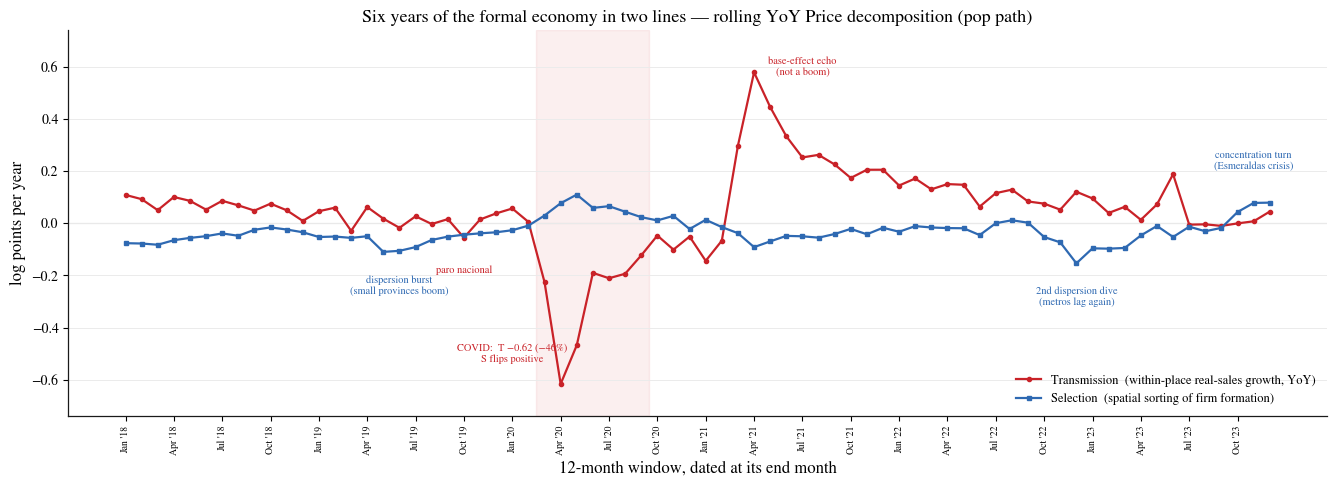


headline 2017M01->2023M01: S = -0.0428/yr  T = +0.0507/yr;  between-province share of selection = 86%


In [2]:
# ==============================================================================
# FIG 1 -- the monthly pop-path series with its six episodes annotated
# ------------------------------------------------------------------------------
# Source: the master driver's rolling-12m run (decomposition_summary.csv, pop
# path, "step" windows). Each point is dated at its END month: "Apr '20" is the
# Apr-2019 -> Apr-2020 change. Episode list = the spike-finder episodes of
# decomp_monthly_analysis_pop, annotated here on one calendar axis.
# ==============================================================================
import calendar

summ = pd.read_csv(MASTER_DIR / "decomposition_summary.csv")
ts = (summ[(summ["path"] == "pop") & (summ["window_type"] == "step")]
      .sort_values("initial_period").reset_index(drop=True))
labels = [f"{calendar.month_abbr[int(p[5:])]} '{p[2:4]}" for p in ts["final_period"]]
xs = np.arange(len(ts))
pos = {p: i for i, p in enumerate(ts["final_period"])}

fig, ax = plt.subplots(figsize=(13.5, 5.0))
ax.axhline(0, color="0.75", lw=0.8, zorder=1)
ax.axvspan(pos["2020M03"] - 0.5, pos["2020M09"] + 0.5, color=TRANS_RED, alpha=0.07, zorder=0)
ax.plot(xs, ts["transmission"], marker="o", ms=3, lw=1.6, color=TRANS_RED,
        label="Transmission  (within-place real-sales growth, YoY)", zorder=3)
ax.plot(xs, ts["selection_total"], marker="s", ms=3, lw=1.6, color=SEL_BLUE,
        label="Selection  (spatial sorting of firm formation)", zorder=3)

EPISODES = [  # (end-month window, label, y anchor, colour)
    ("2019M06", "dispersion burst\n(small provinces boom)", -0.24, SEL_BLUE),
    ("2019M10", "paro nacional",                            -0.18, TRANS_RED),
    ("2020M01", "COVID:  T −0.62 (−46%)\nS flips positive", -0.50, TRANS_RED),
    ("2021M07", "base-effect echo\n(not a boom)",            0.60, TRANS_RED),
    ("2022M12", "2nd dispersion dive\n(metros lag again)",  -0.28, SEL_BLUE),
    ("2023M11", "concentration turn\n(Esmeraldas crisis)",   0.24, SEL_BLUE),
]
for p, lab, y, c in EPISODES:
    x = pos[p]
    ax.annotate(lab, (x, y), ha="center", va="center", fontsize=7.5, color=c)

ax.set_xticks(xs[::3]); ax.set_xticklabels(labels[::3], rotation=90, fontsize=7)
ax.set_ylim(-0.74, 0.74)
ax.set_ylabel("log points per year"); ax.set_xlabel("12-month window, dated at its end month")
ax.set_title("Six years of the formal economy in two lines — rolling YoY Price decomposition (pop path)")
ax.grid(axis="y", color="0.92", lw=0.7)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig1_monthly_series_episodes.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig1_monthly_series_episodes.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig1_monthly_series_episodes.png")
plt.show()

head = summ[(summ["path"] == "pop") & (summ["window_type"] == "headline")].iloc[0]
print(f"\nheadline {head['initial_period']}->{head['final_period']}: "
      f"S = {head['selection_total']:+.4f}/yr  T = {head['transmission']:+.4f}/yr;  "
      f"between-province share of selection = {head['share_between_provinces']:.0%}")

saved -> results/story/fig2_scale_scatters.png


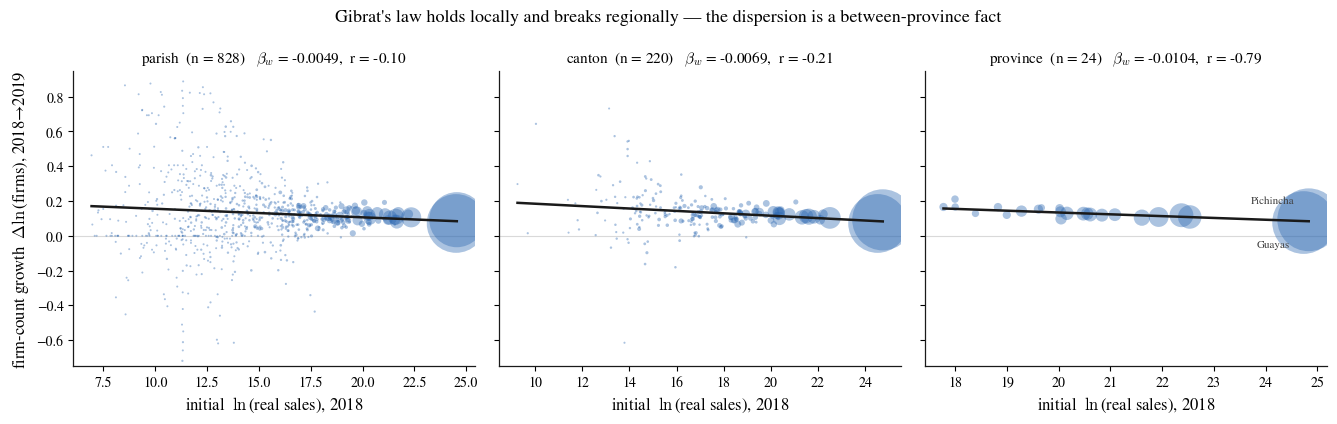

In [3]:
# ==============================================================================
# FIG 2 -- WHERE the dispersion lives: growth vs size at three nested tiers
# ------------------------------------------------------------------------------
# Firm-count growth against initial log real sales for one clean pre-COVID step
# (2018->2019), with each unit = parish / canton / province. Dot area = initial
# firm share, line = firm-share-weighted fit (its tilt x trait variance IS the
# selection covariance). Gibrat's law = a flat cloud. The slope only appears at
# the province tier -- a pooled parish regression would find nothing.
# ==============================================================================
Y0, Y1 = 2018, 2019
surv = sorted(VALID[Y0] & VALID[Y1])
pp = pd.DataFrame({"f0": FIRMS.loc[surv, Y0], "f1": FIRMS.loc[surv, Y1],
                   "s0": SALES.loc[surv, Y0]})

def tier_frame(width):
    if width == 6:
        return pp.copy()
    g = pp.groupby(pp.index.str[:width]).sum()
    return g

def wslope(x, y, w):
    w = w / w.sum()
    xb, yb = (w * x).sum(), (w * y).sum()
    return (w * (x - xb) * (y - yb)).sum() / (w * (x - xb) ** 2).sum()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3), sharey=True)
for ax, (name, width) in zip(axes, [("parish", 6), ("canton", 4), ("province", 2)]):
    t = tier_frame(width)
    x, y = np.log(t["s0"]), np.log(t["f1"] / t["f0"])
    w = t["f0"] / t["f0"].sum()
    b = wslope(x, y, w)
    r = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, s=6e3 * w + 2, alpha=0.4, color=SEL_BLUE, lw=0)
    xb = (w * x).sum()
    xg = np.linspace(x.min(), x.max(), 2)
    ax.plot(xg, (w * y).sum() + b * (xg - xb), color="0.1", lw=1.8)
    ax.axhline(0, color="0.85", lw=0.8, zorder=0)
    if width == 2:
        for code_, nm, dy in [("17", "Pichincha", 12), ("09", "Guayas", -18)]:
            if code_ in t.index:
                ax.annotate(nm, (x[code_], y[code_]), textcoords="offset points",
                            xytext=(-10, dy), ha="right", fontsize=8, color="0.25")
    ax.set_title(f"{name}  (n = {len(t)})   $\\beta_w$ = {b:+.4f},  r = {r:+.2f}", fontsize=11)
    ax.set_xlabel("initial  $\\ln$(real sales), " + str(Y0))
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
axes[0].set_ylabel(f"firm-count growth  $\\Delta\\ln$(firms), {Y0}→{Y1}")
axes[0].set_ylim(-0.75, 0.95)
fig.suptitle("Gibrat's law holds locally and breaks regionally — the dispersion is a between-province fact",
             fontsize=13)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig2_scale_scatters.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig2_scale_scatters.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig2_scale_scatters.png")
plt.show()

**Act 1 verdict.** The engine's scale split says the same thing exactly: of the headline selection, **~86% is the between-province component**; parishes-within-canton contribute ≈ 0. The density-path analysis (`decomp_monthly_analysis_den`) formalises it as a β-convergence regression: between provinces $\beta \approx -0.012$/yr, while within provinces and cantons growth is Gibrat (scale-free), so there is *no local rebalancing force at all*. And the dispersion is fragile: COVID flipped selection positive for a year (the periphery's firm formation collapsed while the metros' held), the late-2022 windows re-concentrated formal activity toward canton seats, and the Esmeraldas security crisis did it again in 2023. **Reforms that aim to formalize and decentralize the economy are leaving a footprint — but it is visible only at the coarsest administrative scale, it moves at generational speed, and every shock spends years of it.**

## ACT 2 — Fragility: an archipelago of monocultures, on two margins

Two facts, one per margin. **The intensive margin (sales) is where shocks bite:** through the deepest crisis in the sample, real sales fell −46% year-over-year at the trough. **The extensive margin (the firm registry) never even dipped** — 100 of 174 analysable parishes never fell below their pre-shock firm stock; the formal registry grew straight through the lockdown. Fragility in Ecuador's formal economy is a *sales* phenomenon, and resilience an *entry* phenomenon — which is why the two Price margins can tell opposite stories about the same place at the same time (Quito: 28th percentile on sales resistance, 75th on firms).

saved -> results/story/fig3_two_margins.png


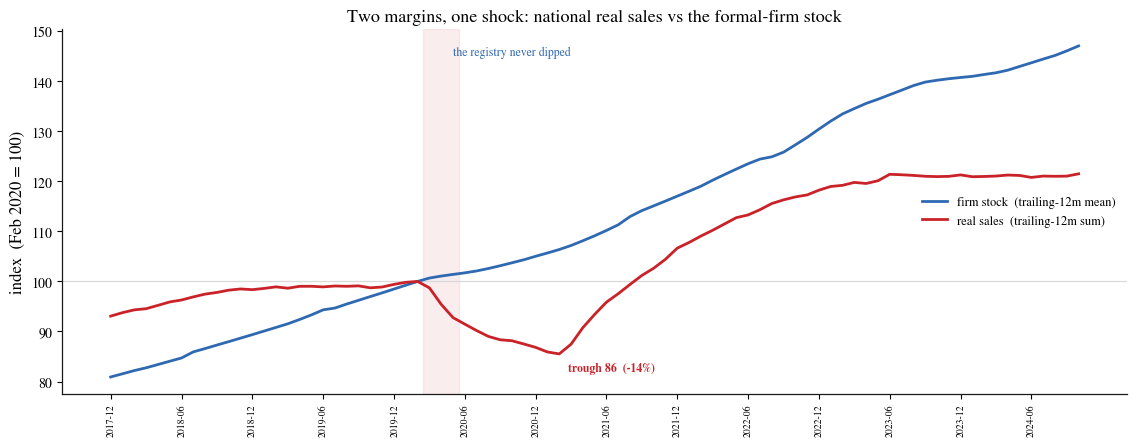

In [4]:
# ==============================================================================
# FIG 3 -- the two margins through COVID: sales cratered, the registry never dipped
# ------------------------------------------------------------------------------
# National trailing-12-month real sales (flow -> rolling sum) and firm stock
# (stock -> rolling mean), indexed to Feb-2020 = 100. Trailing windows need 12
# consecutive months, so the series stops at Oct-2024 (Nov-2024 is missing).
# ==============================================================================
nat = (panel[panel["year"] <= 2024]
       .assign(t=lambda d: pd.PeriodIndex(d["year"].astype(str) + "-"
                                          + d["m"].astype(str).str.zfill(2), freq="M"))
       .groupby("t").agg(sales=("real_sales", "sum"), firms=("total_firms", "sum"))
       .sort_index().loc[:pd.Period("2024-10", "M")])
tr = pd.DataFrame({"sales": nat["sales"].rolling(12).sum(),
                   "firms": nat["firms"].rolling(12).mean()}).dropna()
BASE = pd.Period("2020-02", "M")
idx = tr / tr.loc[BASE] * 100

fig, ax = plt.subplots(figsize=(11.5, 4.6))
ax.axhline(100, color="0.85", lw=0.9, zorder=1)
lock0, lock1 = idx.index.get_loc(pd.Period("2020-03", "M")), idx.index.get_loc(pd.Period("2020-05", "M"))
ax.axvspan(lock0 - 0.5, lock1 + 0.5, color=TRANS_RED, alpha=0.08, zorder=0)
xs3 = np.arange(len(idx))
ax.plot(xs3, idx["firms"], lw=2.0, color=SEL_BLUE, label="firm stock  (trailing-12m mean)")
ax.plot(xs3, idx["sales"], lw=2.0, color=TRANS_RED, label="real sales  (trailing-12m sum)")
tro = idx["sales"].idxmin()
ax.annotate(f"trough {idx.loc[tro,'sales']:.0f}  ({idx.loc[tro,'sales']-100:+.0f}%)",
            (idx.index.get_loc(tro), idx.loc[tro, "sales"]), textcoords="offset points",
            xytext=(6, -12), fontsize=8.5, color=TRANS_RED, fontweight="bold")
ax.text(lock0 + 2, idx["firms"].max(), "the registry never dipped", fontsize=8.5,
        color=SEL_BLUE, va="top")
ax.set_xticks(xs3[::6])
ax.set_xticklabels([str(p) for p in idx.index[::6]], rotation=90, fontsize=7)
ax.set_ylabel("index  (Feb 2020 = 100)")
ax.set_title("Two margins, one shock: national real sales vs the formal-firm stock")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
ax.legend(frameon=False, fontsize=9, loc="center right")
fig.tight_layout()
fig.savefig(STORY_DIR / "fig3_two_margins.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig3_two_margins.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig3_two_margins.png")
plt.show()

saved -> results/story/fig4_province_concentration.png


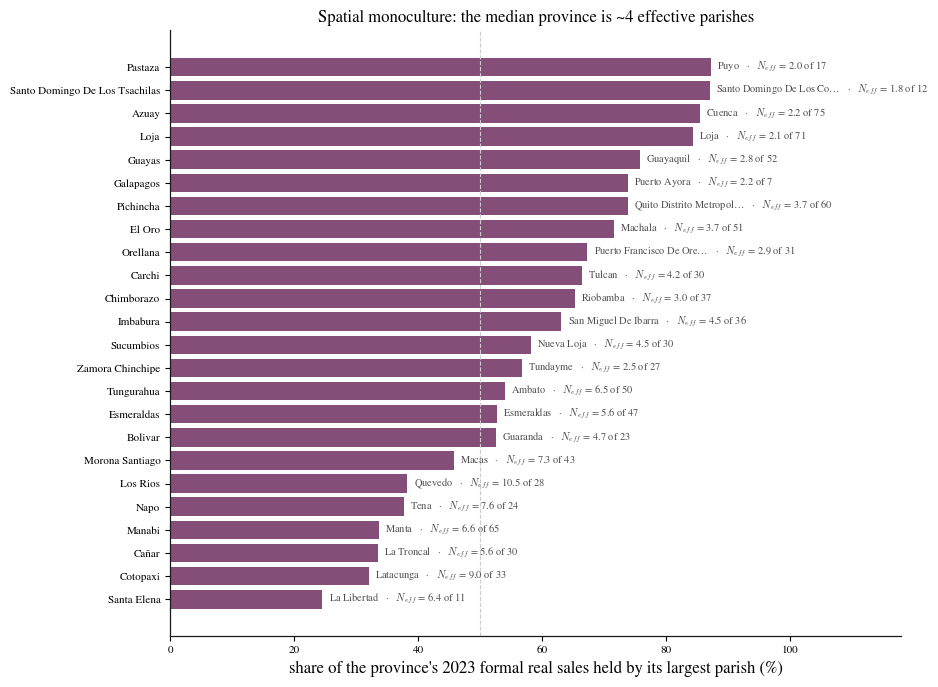

median top-1 share 61%;  median N_eff 4.3


In [5]:
# ==============================================================================
# FIG 4 -- provinces are one town plus statistical noise
# ------------------------------------------------------------------------------
# For every province, 2023 (last complete year): the share of its formal real
# sales booked in its single largest parish, annotated with the effective
# number of parishes N_eff = exp(entropy of parish sales shares).
# ==============================================================================
w23 = panel[panel["year"] == 2023].groupby("cod_parr")["real_sales"].sum()
w23 = w23[w23 > dec.SALES_FLOOR]
rows = []
for prov, s in w23.groupby(w23.index.str[:2]):
    sh = s / s.sum()
    rows.append(dict(prov=PROV.get(prov, prov), top1=sh.max(),
                     neff=float(np.exp(-(sh * np.log(sh)).sum())), n=len(sh),
                     top_parish=PNAME.get(sh.idxmax(), sh.idxmax()).split(" (")[0]))
conc = pd.DataFrame(rows).sort_values("top1")

fig, ax = plt.subplots(figsize=(9.5, 7.0))
ax.barh(conc["prov"], conc["top1"] * 100, color=PURPLE, alpha=0.88)
for i, r in enumerate(conc.itertuples()):
    nm = r.top_parish if len(r.top_parish) <= 24 else r.top_parish[:23] + "…"
    ax.text(r.top1 * 100 + 1, i, f"{nm}   ·   $N_{{eff}}$ = {r.neff:.1f} of {r.n}",
            va="center", fontsize=7.5, color="0.3")
ax.set_xlim(0, 118)
ax.set_xlabel("share of the province's 2023 formal real sales held by its largest parish (%)")
ax.set_title("Spatial monoculture: the median province is ~4 effective parishes", fontsize=12)
ax.axvline(50, color="0.8", lw=0.8, ls="--")
ax.tick_params(labelsize=8)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig4_province_concentration.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig4_province_concentration.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig4_province_concentration.png")
plt.show()
print(f"median top-1 share {conc.top1.median():.0%};  median N_eff {conc.neff.median():.1f}")

saved -> results/story/fig5_composition_fate.png


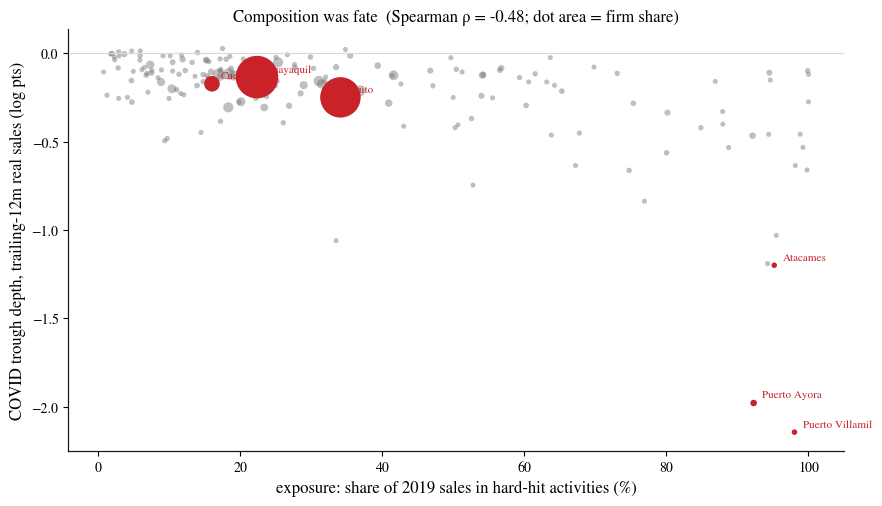

deepest sales troughs (all one-activity places):
                            name  res_sales  rec_sales  hardhit_share  neff_sales
       Puerto Villamil (Isabela)      -2.15       45.0           0.98        3.73
       Puerto Ayora (Santa Cruz)      -1.98       39.0           0.92        2.87
             Atacames (Atacames)      -1.20        NaN           0.95        4.79
               Guamote (Guamote)      -1.19       30.0           0.94        3.97
             Llano Chico (Quito)      -1.06        NaN           0.33        3.95
           Echeandia (Echeandia)      -1.03       20.0           0.95        3.08
El Dorado De Cascales (Cascales)      -0.84       21.0           0.77        4.05
 Urcuqui (San Miguel De Urcuqui)      -0.75       19.0           0.53        6.23


In [6]:
# ==============================================================================
# FIG 5 -- sectoral monoculture is what the shock punished
# ------------------------------------------------------------------------------
# From resilience_analysis' exported metrics: each parish's exposure to the
# hard-hit activities (share of 2019 sales in sections that fell more than the
# national average) against its COVID trough depth. Composition -- not
# diversification per se -- predicts the hit; the famous one-activity places
# sit exactly where the story says.
# ==============================================================================
res = pd.read_csv(paths.RESILIENCE / "resilience_metrics_parish.csv", dtype={"unit": str})
from scipy import stats as sps
rho = sps.spearmanr(res["hardhit_share"], res["res_sales"]).statistic

HOT = {"200350": "Puerto Ayora", "200250": "Puerto Villamil", "080650": "Atacames",
       "170150": "Quito", "090150": "Guayaquil", "010150": "Cuenca"}
fig, ax = plt.subplots(figsize=(9.0, 5.2))
ax.scatter(res["hardhit_share"] * 100, res["res_sales"], s=12 + 3e3 * res["p0"],
           alpha=0.45, color=GRAY, lw=0)
hot = res[res["unit"].isin(HOT)]
ax.scatter(hot["hardhit_share"] * 100, hot["res_sales"], s=14 + 3e3 * hot["p0"],
           color=TRANS_RED, lw=0, zorder=5)
for _, r in hot.iterrows():
    ax.annotate(HOT[r["unit"]], (r["hardhit_share"] * 100, r["res_sales"]),
                textcoords="offset points", xytext=(6, 4), fontsize=8, color=style.RED)
ax.axhline(0, color="0.85", lw=0.8)
ax.set_xlabel("exposure: share of 2019 sales in hard-hit activities (%)")
ax.set_ylabel("COVID trough depth, trailing-12m real sales (log pts)")
ax.set_title(f"Composition was fate  (Spearman ρ = {rho:+.2f}; dot area = firm share)", fontsize=12)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig5_composition_fate.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig5_composition_fate.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig5_composition_fate.png")
plt.show()

print("deepest sales troughs (all one-activity places):")
print(res.nsmallest(8, "res_sales")[["name", "res_sales", "rec_sales", "hardhit_share", "neff_sales"]]
      .round(2).to_string(index=False))

**Act 2 verdict.** The resilience notebook's regressions close the loop: exposure to hard-hit activities is the strongest predictor of the COVID hit (Spearman ≈ −0.5 size-partialled; the Bartik shift-share alone explains 18% of the cross-parish variance with a coefficient ≈ 2), while **diversification per se bought nothing** — the entropy term is ≈ 0 once size, composition and province are controlled, and the "portfolio premise" fails even before the shock (diversity did not lower pre-COVID volatility, size-partialled). When the shock is *correlated*, only *which* activities you hold matters — and most of Ecuador's places hold one: the deepest, longest craters are all tourism gateways (Puerto Villamil −2.1 log pts, 45 months under water; Puerto Ayora −2.0, 39 months; Atacames *still* not recovered by Oct-2024), oil towns, and single-mineral towns. The fragility map is therefore two overlaid monocultures: provinces that are one parish (Fig 4), and parishes that are one activity (Fig 5).

## ACT 3 — Showing the invisible: growth that one parish produces alone

**The case.** Zamora Chinchipe hosts **Fruta del Norte** (Lundin Gold), Ecuador's first large-scale gold mine, in the parish of **Los Encuentros (Yantzaza)**: first pour November 2019, commercial production 2020. In the SRI panel this is about a dozen formal firms. Watch what they do to a province of ~220:

A provincial GDP dashboard sees Zamora Chinchipe "growing". The question a dashboard cannot answer is *who is that growth* — and the per-unit ledger behind the Price decomposition answers it by construction, because every aggregate number is an exact sum of named places' contributions.

saved -> results/story/fig6_zamora.png


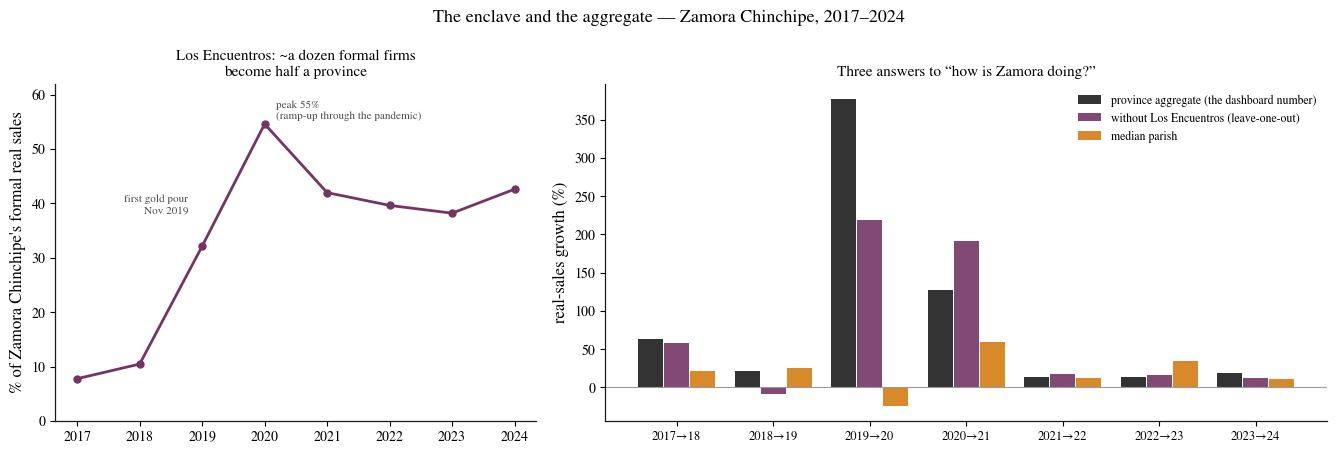

Los Encuentros' contribution to the province's sales increase, by step:
   step  aggregate_%  without_LE_%  median_parish_%  LE_share_of_Δ_%
2017→18         62.6          57.8             20.8             14.8
2018→19         20.8          -8.4             25.7            136.3
2019→20        376.9         219.0            -23.9             60.6
2020→21        127.6         190.9             59.6             32.1
2021→22         12.8          17.4             12.2             21.3
2022→23         13.1          15.7             34.0             27.2
2023→24         18.2          11.5             11.2             61.5


In [7]:
# ==============================================================================
# FIG 6 -- Zamora Chinchipe: the enclave and the masked aggregate
# ------------------------------------------------------------------------------
# (a) Los Encuentros' share of the province's formal real sales, 2017-2024.
# (b) For every annual step: the province's aggregate sales growth (the
#     "dashboard" number), the same growth WITHOUT Los Encuentros (leave-one-
#     out), and the MEDIAN parish's growth (the democratic number). 2023->24
#     uses the 11 months present in both years.
# ==============================================================================
LE = "190553"
zz = panel[panel["cod_parr"].str.startswith("19") & (panel["year"] <= 2024)]
ann = zz.groupby(["cod_parr", "year"])["real_sales"].sum()
le_share = (ann.loc[LE] / ann.groupby("year").sum() * 100).reindex(range(2017, 2025))

steps = [(y, y + 1) for y in range(2017, 2024)]
rows = []
for y0, y1 in steps:
    w = parish_sales(y0, y1)
    z = w[w.index.str.startswith("19")]
    g = np.log(z[y1] / z[y0])
    G = np.log(z[y1].sum() / z[y0].sum())
    Gwo = np.log(z.drop(LE, errors="ignore")[y1].sum() / z.drop(LE, errors="ignore")[y0].sum())
    rows.append(dict(step=f"{y0}→{str(y1)[2:]}", G=np.expm1(G) * 100,
                     Gwo=np.expm1(Gwo) * 100, med=np.expm1(g.median()) * 100,
                     shr=(z[y1] - z[y0]).get(LE, 0.0) / (z[y1].sum() - z[y0].sum()) * 100))
zt = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6), gridspec_kw={"width_ratios": [1, 1.5]})
axes[0].plot(le_share.index, le_share.values, marker="o", ms=5, lw=2.0, color=PURPLE)
axes[0].annotate("first gold pour\nNov 2019", (2019, le_share[2019]), textcoords="offset points",
                 xytext=(-10, 24), ha="right", fontsize=8, color="0.3")
axes[0].annotate(f"peak {le_share[2020]:.0f}%\n(ramp-up through the pandemic)", (2020, le_share[2020]),
                 textcoords="offset points", xytext=(8, 4), fontsize=8, color="0.3")
axes[0].set_ylabel("% of Zamora Chinchipe's formal real sales")
axes[0].set_title("Los Encuentros: ~a dozen formal firms\nbecome half a province", fontsize=11)
axes[0].set_ylim(0, 62)

xb = np.arange(len(zt))
axes[1].bar(xb - 0.27, zt["G"],   width=0.26, color="0.2",  label="province aggregate (the dashboard number)")
axes[1].bar(xb,        zt["Gwo"], width=0.26, color=PURPLE, alpha=0.9, label="without Los Encuentros (leave-one-out)")
axes[1].bar(xb + 0.27, zt["med"], width=0.26, color=ORANGE, alpha=0.9, label="median parish")
axes[1].axhline(0, color="0.6", lw=0.8)
axes[1].set_xticks(xb); axes[1].set_xticklabels(zt["step"], fontsize=9)
axes[1].set_ylabel("real-sales growth (%)")
axes[1].set_title("Three answers to “how is Zamora doing?”", fontsize=11)
axes[1].legend(frameon=False, fontsize=8.5, loc="upper right")
for ax in axes:
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.suptitle("The enclave and the aggregate — Zamora Chinchipe, 2017–2024", fontsize=13)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig6_zamora.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig6_zamora.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig6_zamora.png")
plt.show()

print("Los Encuentros' contribution to the province's sales increase, by step:")
print(zt.assign(**{c: zt[c].round(1) for c in ("G", "Gwo", "med", "shr")})
      .rename(columns={"G": "aggregate_%", "Gwo": "without_LE_%", "med": "median_parish_%",
                       "shr": "LE_share_of_Δ_%"}).to_string(index=False))

saved -> results/story/fig7_two_ledgers.png


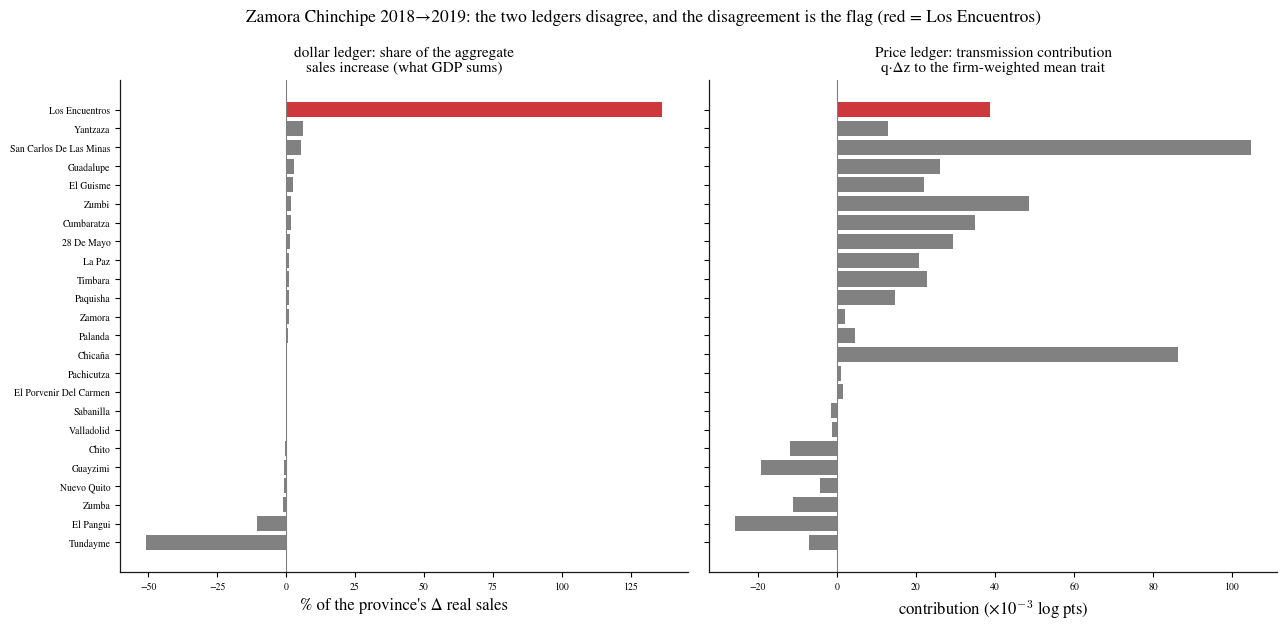

within-Zamora Price (2018->2019, pop path):  Δz̄ = +0.3246  =  S -0.0643  +  T +0.3889
Los Encuentros: dollar-ledger share +136% of Δ aggregate sales;  Price trans_c +0.0388 (rank 4 of 24);  own Δz +1.31 (+271%) on p = 2.7% of firms
aggregate-sales growth +0.189  vs firm-weighted mean-trait change +0.3246 — the wedge is the enclave


In [8]:
# ==============================================================================
# FIG 7 -- two ledgers, one province-year: why the decomposition flags the enclave
# ------------------------------------------------------------------------------
# Zamora 2018->2019, the mine's first production year. LEFT: each parish's
# share of the change in AGGREGATE sales (the dollar ledger a GDP number
# implicitly sums) -- Los Encuentros dwarfs everything. RIGHT: each parish's
# transmission contribution q*dz to the FIRM-WEIGHTED mean trait (the Price
# ledger, one-firm-one-vote) -- Los Encuentros is unremarkable, because ~5
# firms carry almost no weight. The DISAGREEMENT of the two ledgers is the
# enclave signature: the dollars moved; the typical firm's place barely did.
# ==============================================================================
Y0, Y1 = 2018, 2019
w = parish_sales(Y0, Y1); w = w[w.index.str.startswith("19")]
d = panel[panel["cod_parr"].isin(w.index) & panel["year"].isin([Y0, Y1])]
f = d.groupby(["cod_parr", "year"])["total_firms"].mean().unstack().loc[w.index]

n0, n1 = f[Y0], f[Y1]
z0, z1 = np.log(w[Y0]), np.log(w[Y1])
p, q = n0 / n0.sum(), n1 / n1.sum()
W, Z0 = ((p * n1 / n0)).sum(), (p * z0).sum()
sel_c = p * ((n1 / n0) / W - 1) * (z0 - Z0)
tr_c = q * (z1 - z0)
dollar = (w[Y1] - w[Y0]) / (w[Y1].sum() - w[Y0].sum())

tbl = pd.DataFrame({"dollar": dollar, "price": tr_c}).sort_values("dollar")
names = [PNAME.get(i, i).split(" (")[0] for i in tbl.index]
hot = [TRANS_RED if i == LE else GRAY for i in tbl.index]

ypos = np.arange(len(tbl))
fig, axes = plt.subplots(1, 2, figsize=(13.0, 6.4), sharey=True)
axes[0].barh(ypos, tbl["dollar"] * 100, color=hot, alpha=0.9)
axes[0].set_yticks(ypos)
axes[0].set_yticklabels(names, fontsize=7)
axes[0].set_title("dollar ledger: share of the aggregate\nsales increase (what GDP sums)", fontsize=11)
axes[0].set_xlabel("% of the province's Δ real sales")
axes[1].barh(ypos, tbl["price"] * 1e3, color=hot, alpha=0.9)
axes[1].set_title("Price ledger: transmission contribution\nq·Δz to the firm-weighted mean trait", fontsize=11)
axes[1].set_xlabel("contribution (×10$^{-3}$ log pts)")
for ax in axes:
    ax.axvline(0, color="0.5", lw=0.8)
    ax.tick_params(labelsize=7)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
fig.suptitle(f"Zamora Chinchipe {Y0}→{Y1}: the two ledgers disagree, and the disagreement is the flag "
             f"(red = Los Encuentros)", fontsize=12.5)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig7_two_ledgers.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig7_two_ledgers.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig7_two_ledgers.png")
plt.show()

print(f"within-Zamora Price ({Y0}->{Y1}, pop path):  Δz̄ = {(sel_c + tr_c).sum():+.4f}"
      f"  =  S {sel_c.sum():+.4f}  +  T {tr_c.sum():+.4f}")
print(f"Los Encuentros: dollar-ledger share {dollar[LE]:+.0%} of Δ aggregate sales;"
      f"  Price trans_c {tr_c[LE]:+.4f} (rank {int((tr_c.rank(ascending=False))[LE])} of {len(tr_c)});"
      f"  own Δz {z1[LE]-z0[LE]:+.2f} ({np.expm1(z1[LE]-z0[LE]):+.0%}) on p = {p[LE]:.1%} of firms")
print(f"aggregate-sales growth {np.log(w[Y1].sum()/w[Y0].sum()):+.3f}"
      f"  vs firm-weighted mean-trait change {(sel_c+tr_c).sum():+.4f} — the wedge is the enclave")

### How the decomposition flags what the macro number hides

Three readings of the same province-year, and only the third is complete:

1. **The dashboard reading** (aggregate growth): Zamora 2018→19 grew **+20.8%**. True, and profoundly incomplete.
2. **The leave-one-out reading**: without Los Encuentros the aggregate is **−8.4%** — the growth is one parish. But this alone over-corrects: the *median* parish grew +26% that year (the pre-COVID dispersion burst that the monthly series flags in exactly these windows, with Zamora named among the booming small provinces). Three things happened at once — a broad small-parish boom, a declining provincial capital, and an exploding enclave — and **no single scalar can represent that**.
3. **The ledger reading** (Fig 7): the *dollar ledger* attributes essentially the whole aggregate increase to Los Encuentros; the *Price ledger* — where each parish's transmission contribution $q_i\,\Delta z_i$ is weighted by its share of *firms*, one-firm-one-vote — barely notices it (~5 firms, rank ~4 of 24, on 2.7% of the firm weight). **The wedge between the aggregate (+0.19 log pts) and the firm-weighted mean trait (+0.32) is the enclave signature.** When the two ledgers agree, growth is broad; when they diverge, the money and the typical firm's experience have decoupled. The pop path (firm-weighted) and inc path (sales-weighted) of the decomposition institutionalise exactly this comparison — the inc path *would* book Los Encuentros as a huge positive selection term (sales reallocating toward one unit), while the pop path reports the broad dispersion. Running both *is* the audit.

And the mask repeats at pandemic scale: in 2019→20 the province's aggregate grew **+377%** — the mine ramped to full production straight through the lockdown — while the **median Zamora parish shrank −24%**: a "boom province" whose typical parish was living the national COVID collapse. (Zamora in fact hosts *two* simultaneous enclaves — **Mirador**, the copper mine in Tundayme (El Pangui), also started up in mid-2019 — which is why even the leave-one-out number stays large that year, and why Tundayme swings so violently in the dollar ledger.)

Two honesty notes. First, the 2023→24 window is a *partial* mask: Los Encuentros contributes ~61% of the increase and 11 of 27 parishes shrank, but the median parish did grow (+10.6%) — the pure textbook case is 2018→19. Second, a naive 2024 annual total (missing November) makes the masking look *total* (+7.6% aggregate collapsing to −0.1% without the mine) — an artifact worth remembering as its own cautionary tale about aggregate numbers.

### The general detector — three numbers per (province, window)

Everything needed is already in the per-unit tables the decomposition exports; the detector just reads them side by side. For each province $P$ and window $t$, over the surviving parishes:

1. **Aggregate growth** $G = \Delta\ln\sum_{i\in P} y_i$ — the dashboard number;
2. **Leave-one-out growth** $G_{-1}$ — the same, dropping the parish with the largest $|\Delta y_i|$;
3. **Median unit growth** $\tilde g = \operatorname{median}_i\,\Delta\ln y_i$ — the democratic number.

Flags: **masked growth** when $G$ is clearly positive but $G_{-1}$ is ≈ 0 or negative (or the gap $G - G_{-1}$ is most of $G$); **masked decline** — the mirror case, just as distorting — when $G$ is clearly negative but $G_{-1}$ is fine. The top unit's share of the change and the count of shrinking parishes complete the report card.

saved -> results/story/fig8_masked_growth_scan.png


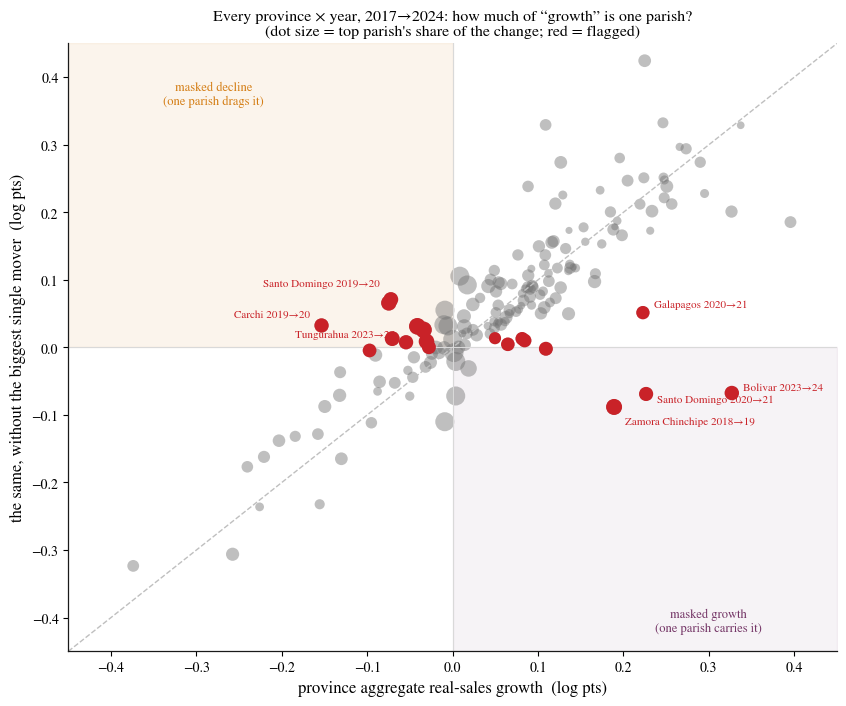


MASKED GROWTH (aggregate up >2%, gone without one parish):
                          prov    step  n  G_agg  G_wo   med  n_shrink                                            top  top_dshare
                       Bolivar 2023→24 23   38.7  -6.5   6.0        11                            Guaranda (Guaranda)       108.0
Santo Domingo De Los Tsachilas 2020→21 12   25.4  -6.7  12.3         3 Santo Domingo De Los Colorados (Santo Domingo)       104.0
                     Galapagos 2020→21  7   25.0   5.3  61.5         1                      Puerto Ayora (Santa Cruz)        91.0
              Zamora Chinchipe 2018→19 24   20.8  -8.4  25.7         8           Los Encuentros (Yantzaza (Yanzatza))       136.0
                       Bolivar 2017→18 18   11.5  -0.2   7.3         8                            Guaranda (Guaranda)       101.0
                    Chimborazo 2022→23 34    8.8   1.0  16.8        11                            Riobamba (Riobamba)        96.0
                    Esmeraldas

In [9]:
# ==============================================================================
# FIG 8 + tables -- the national masked-growth scan, 2017->2024
# ------------------------------------------------------------------------------
# Every province x annual step. A point ON the diagonal = growth robust to
# removing its biggest mover; the farther BELOW the diagonal, the more one
# parish carries. Southeast quadrant = masked growth (aggregate up, rest flat
# or down); northwest = masked decline. Saves the full scan to story/.
# ==============================================================================
scan = []
for y0, y1 in [(y, y + 1) for y in range(2017, 2024)]:
    w = parish_sales(y0, y1)
    for prov, grp in w.groupby(w.index.str[:2]):
        if len(grp) < 3:
            continue
        g = np.log(grp[y1] / grp[y0])
        G = np.log(grp[y1].sum() / grp[y0].sum())
        top = (grp[y1] - grp[y0]).abs().idxmax()
        Gwo = np.log(grp.drop(top)[y1].sum() / grp.drop(top)[y0].sum())
        scan.append(dict(prov=PROV.get(prov, prov), step=f"{y0}→{str(y1)[2:]}",
                         n=len(grp), G_agg=G, G_wo=Gwo, med=g.median(),
                         n_shrink=int((g < 0).sum()),
                         top=PNAME.get(top, top), top_dshare=(grp.loc[top, y1] - grp.loc[top, y0]) / (grp[y1].sum() - grp[y0].sum())))
scan = pd.DataFrame(scan)
scan.to_csv(STORY_DIR / "masked_growth_scan.csv", index=False)

m_grow = scan[(scan.G_agg > 0.02) & ((scan.G_wo < 0.005) | (scan.G_agg - scan.G_wo > 0.7 * scan.G_agg))]
m_decl = scan[(scan.G_agg < -0.02) & (scan.G_wo > -0.005)]

fig, ax = plt.subplots(figsize=(8.6, 7.2))
lim = (-0.45, 0.45)
ax.fill_between([0, lim[1]], lim[0], 0, color=PURPLE, alpha=0.06)
ax.fill_between([lim[0], 0], 0, lim[1], color=ORANGE, alpha=0.08)
ax.plot(lim, lim, color="0.75", lw=1.0, ls="--")
ax.axhline(0, color="0.85", lw=0.8); ax.axvline(0, color="0.85", lw=0.8)
ax.scatter(scan.G_agg, scan.G_wo, s=8 + 90 * scan.top_dshare.abs().clip(0, 2),
           alpha=0.45, color=GRAY, lw=0)
flag = pd.concat([m_grow, m_decl])
ax.scatter(flag.G_agg, flag.G_wo, s=10 + 90 * flag.top_dshare.abs().clip(0, 2),
           color=TRANS_RED, lw=0, zorder=5)
LABELS = {("Zamora Chinchipe", "2018→19"): (8, -12), ("Bolivar", "2023→24"): (8, 2),
          ("Santo Domingo De Los Tsachilas", "2020→21"): (8, -6),
          ("Carchi", "2019→20"): (-8, 6), ("Santo Domingo De Los Tsachilas", "2019→20"): (-8, 10),
          ("Tungurahua", "2023→24"): (-8, 4), ("Galapagos", "2020→21"): (8, 4)}
for _, r in flag.iterrows():
    key = (r["prov"], r["step"])
    if key in LABELS:
        dx, dy = LABELS[key]
        ax.annotate(f"{r['prov'].replace(' De Los Tsachilas','')} {r['step']}",
                    (r.G_agg, r.G_wo), textcoords="offset points", xytext=(dx, dy),
                    ha="left" if dx > 0 else "right", fontsize=8, color=style.RED)
ax.text(0.30, -0.42, "masked growth\n(one parish carries it)", fontsize=9, color=PURPLE, ha="center")
ax.text(-0.28, 0.36, "masked decline\n(one parish drags it)", fontsize=9, color=style.ORANGE, ha="center")
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("province aggregate real-sales growth  (log pts)")
ax.set_ylabel("the same, without the biggest single mover  (log pts)")
ax.set_title("Every province × year, 2017→2024: how much of “growth” is one parish?\n"
             "(dot size = top parish's share of the change; red = flagged)", fontsize=11.5)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(STORY_DIR / "fig8_masked_growth_scan.png", dpi=200, bbox_inches="tight")
fig.savefig(STORY_DIR / "fig8_masked_growth_scan.pdf", bbox_inches="tight")
print("saved ->", STORY_DIR / "fig8_masked_growth_scan.png")
plt.show()

fmt = dict(G_agg=lambda d: (np.expm1(d.G_agg) * 100).round(1),
           G_wo=lambda d: (np.expm1(d.G_wo) * 100).round(1),
           med=lambda d: (np.expm1(d.med) * 100).round(1),
           top_dshare=lambda d: (d.top_dshare * 100).round(0))
cols = ["prov", "step", "n", "G_agg", "G_wo", "med", "n_shrink", "top", "top_dshare"]
print("\nMASKED GROWTH (aggregate up >2%, gone without one parish):")
print(m_grow.sort_values("G_agg", ascending=False).assign(**fmt)[cols].to_string(index=False))
print("\nMASKED DECLINE (aggregate down >2%, fine without one parish):")
print(m_decl.sort_values("G_agg").assign(**fmt)[cols].to_string(index=False))
print(f"\nflagged: {len(m_grow)} masked-growth + {len(m_decl)} masked-decline of {len(scan)} province-years"
      f"  ->  {STORY_DIR / 'masked_growth_scan.csv'}")

### The other cases — Zamora is a genre, not an anecdote

**Masked growth.** *Bolívar 2023→24*: aggregate **+39%**, **−7% without Guaranda** (11 of 23 parishes shrank). *Santo Domingo 2020→21*: +25% that is −7% without its capital (which books ~88–89% of the province — a one-parish province by construction). *Chimborazo 2022→23* (Riobamba), *Napo 2018→19* (Tena, median parish −9%), and *Morona Santiago 2023→24* — aggregate +5% while **22 of 36 parishes shrank and the median parish fell −27%**: growth on the dashboard, contraction on the ground.

**Masked decline — the mirror, and just as political.** *Carchi 2019→20*: aggregate **−14%**, but **+3% without Tulcán** — that is the closed Colombian border crushing one entrepôt, not a provincial collapse; a stabilization program sized on the provincial number would mis-target twenty healthy parishes. *Tungurahua 2023→24* (Ambato), *Napo 2023→24* (Tena), *Cotopaxi 2019→20* (Latacunga).

The same aggregation error manufactures both invisible stagnation and invisible health — which is exactly why the audit must be systematic (the scan above is one loop over tables the pipeline already exports) rather than anecdotal.

## ACT 4 — The policy coda: what "selection only at the coarsest scale" means, and what to do with it

**What the finding says, operationally.** The only spatial margin on which Ecuador's formal economy *spontaneously* rebalances is **between provinces** — and there, slowly ($\beta \approx -0.012$/yr, half-life ≈ 56 years). Within provinces and within cantons, firm formation is Gibrat: size-blind, with **no built-in force** pulling activity toward smaller places. And the one operating margin is *shock-reversible*: COVID, the late-2022 windows and the 2023 security crisis each flipped it toward re-concentration.

**Five implications for policy makers.**

1. **Target the margin that actually moves.** Decentralization instruments (infrastructure, credit programs, tax differentials, relocation incentives) implicitly assume a rebalancing tendency they can amplify. That tendency exists *only between provinces*. Sub-provincial place-based policy is not riding a current — it must *create* one, which is a different (and more expensive) kind of intervention. Conversely, between-province instruments work with the grain of the data.
2. **"Wait for convergence" is not a policy.** At the measured speed, halving the Quito–Guayaquil primacy takes two generations. If spatial deconcentration is a goal on political timescales, it requires active instruments; the decomposition provides the baseline speed against which any instrument's effect would be measurable within a few years of monthly windows.
3. **Territorial policy must be counter-cyclical.** Every downturn in the sample — pandemic, post-2022 slowdown, security crisis — was paid for disproportionately by *peripheral firm formation*, clawing back years of dispersion. Emergency support that is spatially blind (or metro-biased, where administrative capacity lives) amplifies exactly this. The monthly selection series is, in effect, a **real-time re-concentration alarm**.
4. **Evaluate formalization reforms at the right scale.** A reform evaluation regressed on parish or canton outcomes will conclude "no spatial effect" *even when the effect exists*, because the signal lives one aggregation level up. The multiscale split (parish-in-canton / canton-in-province / between-province) is the correct evaluation design — and the near-zero fine-scale components are the *control* that makes the coarse-scale signal credible. The late-2022 within-canton flip toward canton seats is the kind of regime change (RIMPE's first full year, among other candidates) this design can date to the month.
5. **Audit growth before celebrating or transferring on it.** Royalty distribution, intergovernmental transfers and "provincial performance" narratives all consume aggregate growth numbers. The three-number detector (aggregate / leave-one-out / median) plus the two-ledger comparison turns those numbers into an *accountability instrument*: Zamora's +21% was one mine; Carchi's −14% was one border town. For mining specifically, the ledger quantifies the diffusion question directly — after five years of Fruta del Norte, Los Encuentros holds ~43% of the province's formal sales while the median Zamora parish's gains remain modest; whether royalties and local-content rules are widening that footprint is now a measurable, monthly question.

**Can they help? Concretely, yes.** Everything in this notebook is computed from data the Ecuadorian state already owns (SRI filings). A ministry or the central bank could run, in-house and monthly, a three-panel territorial monitor: **(i)** the selection/transmission series by scale (the dispersion pulse and its re-concentration alarms), **(ii)** the masked-growth scan (which provincial numbers are one parish), and **(iii)** the fragility map (spatial × sectoral monoculture exposure, which predicted the COVID incidence better than any diversity index). None of it requires new data collection — only the discipline of reading growth as a *ledger of named places* rather than a scalar.

## Caveats and next steps

- **Fiscal domicile.** SRI sales are booked where the firm is registered. Los Encuentros' \$1.1B is real local production, but the same mechanism inflates "Quito" with HQ bookings of national firms — the enclave lens and the HQ-bias caveat are the same coin, and any policy use needs establishment-level or ruc-branch data to sharpen it.
- **Survivors only, formal only.** The decomposition covers continuing formal units (no entry/exit terms at the parish level), and the informal half of Ecuador's economy is invisible here by construction — the results speak to the *formal private* economy's geography, which is precisely the object formalization policy acts on.
- **2024 is incomplete** (November missing): every 2023→24 number here uses the 11 shared months; re-run when the parquet closes the year. Data through 2025M11 already exists in the panel, so the 2024→25 windows are computable the same way.
- **Next analytical step**: align the monthly selection series against the reform calendar (RIMPE 2022, the 2019–21 tax packages) and test the late-2022 within-canton flip as a formalization-regime event; and re-run the masked-growth scan at the canton level, where the enclave phenomenon (Camilo Ponce Enríquez, the oil cantons) likely repeats one tier down.